In [ ]:
!pip install torch
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
from scipy.integrate import solve_ivp
from IPython.display import display, HTML
from mpl_toolkits.mplot3d import Axes3D
import time

!pip install "pina-mathlab"
from pina import Condition, Trainer
from pina.problem import SpatialProblem
from pina.operator import laplacian
from pina.model import FeedForward
from pina.model.block import PeriodicBoundaryEmbedding
from pina.solver import PINN
from pina.domain import CartesianDomain
from pina.equation import Equation
from pina.callback import MetricTracker
#importing everything from PINA tutorial 9

# Physics-Informed Neural Networks to Solve Differential Equations

## Abstract

Physics-informed neural networks provide a flexible way of solving differential equations by embedding the governing physics directly into the training loss of a neural network. This project investigates how PINNs can be applied to increasingly complex differential equations: a simple 1D ODE, the heat equation, the wave equation, and a pressure Poisson problem from fluid dynamics. The aim is not to show PINNs always outperform classic numerical solvers but to study where they are stronger and what limitations they have. The results show that PINNs are advantageous because they give continuous differentiable approximations to the solution and natively incorporate boundary/initial conditions through automatic differentiation so are highly adaptable. The classic solvers remain faster and more reliable for many low dimension problems, but PINNs offer a mesh-free framework for more broad applications, especially where irregular domains or repeated evaluations are important.



# 1. Introduction to PINNs

Traditional numerical methods for solving differential equations, such as finite difference and finite element techniques, rely on discretising the domain into meshes which can become computationally expensive and difficult to construct for high-dimensional problems. These approaches often require careful tuning and can lose accuracy or efficiency as problem complexity increases. More recently, neural networks have emerged as an alternative framework that can approximate solutions continuously across the domain without requiring a predefined mesh. This mesh-free property allows them to handle these complex geometries and higher-dimensional systems more flexibly. Physics-Informed Neural Networks (PINNs) incorporate governing differential equations directly into the training process, allowing accurate and physically consistent solutions.

An artificial neural network is a highly expressive family of parameterised functions designed to map input data to desired outputs. This mapping is achieved by composing multiple simpler functions, commonly referred to as "layers." For a network with $L$ layers, the overall model can be mathematically represented as

$$
NN_{\theta} = f^{(L)} \circ f^{(L-1)} \circ \dots \circ f^{(1)},
$$

where $\theta$ represents the tunable parameters of the network. In a standard fully connected layer, an input vector $x$ is transformed via a weight matrix $w$ and a bias vector $b$. This linear transformation is immediately followed by a non-linear activation function $\phi$ (like a Sigmoid or ReLU function), giving an output of

$$
\phi(w \cdot x + b).
$$

The non-linearity is a crucial component because without it, the composed layers would collapse into a single linear transformation. It is this successive layering of these non-linear transformations that allows the network to approximate highly complex functions.

To force the neural network to make accurate predictions, its parameters $\theta$ must be tuned through a process called training. Training involves minimising a loss function, which quantitatively measures the discrepancy between the network's current predictions and the true target values. Minimising this loss function is typically achieved using an algorithm called gradient descent, which iteratively updates the network's weights and biases in the direction of the steepest descent of the loss landscape.

Calculating the gradients of the loss function with respect to thousands or even millions of parameters is not feasible using numerical solvers so instead it can be done computationally via automatic differentiation (AD). By the chain rule, you can evaluate these derivatives by propagating gradients through the layered structure of the network. There are two primary algorithms for accumulating these gradients: forward accumulation and backward accumulation.

Forward accumulation computes the derivatives moving from the input layer towards the output layer. Conceptually this is straightforward but it requires evaluating computationally expensive matrix-matrix multiplications at each step, making it prohibitively slow for models with large numbers of parameters. Backward accumulation, or reverse-mode backpropagation, computes the derivatives starting from the output (the loss function) backwards to the inputs. By propagating a vector rather than a matrix, backpropagation reduces the sequence of calculations to matrix-vector multiplications. This greatly reduces time complexity at the cost of requiring more memory to store intermediate layer outputs. 

This project will use the PyTorch library to implement this reverse-mode AD natively beneath the surface, although other opensource software libraries like Jax and Tensorflow can also be used to train NNs. An implementation of a feedforward NN using PyTorch which defines a hidden layer, applies a non-linear activation function and executes the forward pass (needed before backpropagation) would look like this:


In [5]:
# intro_feedforward_NN.py

class SimpleNetwork(nn.Module):
    def __init__(self):
        '''initialises PINN'''
        super().__init__()
        # define linear hidden layer: 1 input, 10 output
        self.hidden_layer = nn.Linear(1, 10)
        # define nonlinear activation function
        self.activation = nn.Tanh()
        # define final output layer: 10 hidden to 1 output
        self.output_layer = nn.Linear(10, 1)

    def forward(self, x):
        '''executes forward pass'''
        z = self.activation(self.hidden_layer(x))
        return self.output_layer(z)

Standard NNs rely on massive datasets of observed inputs/outputs to minimise their loss function but this is often insufficient for physical systems where empirical data might be sparse or noisy, or just difficult to obtain. However, physical systems are governed by Ordinary Differential Equations (ODEs) or Partial Differential Equations (PDEs). PINNs embed these directly into the neural network's optimisation process $^{[1]}$.

In a PINN, the loss function is modified to include the standard  error term ($L_{\text{data}}$) and also a penalty term ($L_{\text{PDE}}$). The total loss function takes the form:

$$
L_{\text{total}} = w_{\text{data}} L_{\text{data}} + w_{\text{PDE}} L_{\text{PDE}}.
$$

where $w_{\text{data}}$ and $w_{\text{PDE}}$ are weighting coefficients used to balance. The term $L_{\text{PDE}}$ evaluates the residual of the differential equation using the network's predictions. Because PyTorch continuously tracks the exact analytical derivatives of the network's outputs with respect to its inputs (spatial and temporal coordinates) via AD, the PDE residual can be calculated exactly without relying on numerical approximations or discrete finite grids. By applying a penalty to the network whenever its predictions violates the governing physics, the network is continuously forced into a solution space that is physically consistent. This ultimately reduces the amount of empirical data required to train the model drastically, ensuring highly accurate extrapolations even outside of the training data boundaries $^{[2]}$.

This paper explores the practical implementation and evaluation of PINNs using PyTorch. Section 2 introduces the methodology by solving a classic ODE, and comparing errors and efficiency against a traditional SciPy numerical solver. Section 3 extends this to Partial Differential Equations, specifically the Heat/Diffusion, Wave, and pressure Poisson equations, discussing errors and methodology within each respective subsection. Finally, Section 4 evaluates PINNs against conventional methods overall and concludes.

# 2. Solving non-oscillatory ODEs

## 2.1 Analysis of the computational physics

Before moving to multidimensional systems, we validate the PINN workflow on a simple one dimensional ODE. The first application is a non-oscillatory exponential decay of

$$
\frac{du}{dt} + \lambda u = 0,
$$

with initial condition

$$
u(0)=1.
$$

The analytical solution is

$$
u(t)=e^{-\lambda t}.
$$

This example is a useful baseline because it isolates the mechanics of a PINN without introducing spectral bias or oscillatory behaviour and the PINN only has to learn a smooth monotonic trajectory, and the physics residual requires only a first derivative to be calcualted. More complicated oscillatory behaviour will be investigated in later sections. 

To solve this system using a PINN, the neural network has to be structured to map the scalar time input $t$ to the scalar output $u(t)$. `1D_ODE.py` demonstrates the PyTorch implementation of this architecture. Because of the nonlinear dynamics of the oscillator, a deeper multi-layer perceptron (MLP) which uses multiple hidden layers is used than the single one in `intro_feedforward_nn.py`


In [6]:
# 1D_ODE.py: defining the PINN

class DecayPINN(nn.Module):
    def __init__(self, hidden_neurons=32, hidden_layers=3, activation=nn.Tanh):
        """
        PINN architecture mapping time t to the scalar solution u(t)
        Default tanh activation is smooth and non-oscillatory
        """
        super().__init__()
        layers = []

        # Input layer: one time coordinate -> hidden representation
        layers.append(nn.Linear(1, hidden_neurons))
        layers.append(activation())

        # Hidden layers
        for i in range(hidden_layers - 1):
            layers.append(nn.Linear(hidden_neurons, hidden_neurons))
            layers.append(activation())

        # Output layer: hidden representation -> scalar u(t)
        layers.append(nn.Linear(hidden_neurons, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, t):
        """evaluate the network at time coordinate(s) t"""
        return self.network(t)

if __name__ == "__main__":
    model = DecayPINN()
    t_test = torch.tensor([[0.5]], requires_grad=True)
    u_test = model(t_test)

    print(f"Input t shape: {t_test.shape}, value: {t_test.item()}")
    print(f"Output u shape: {u_test.shape}, value: {u_test.item():.4f}")
    print("Forward pass successful")


Input t shape: torch.Size([1, 1]), value: 0.5
Output u shape: torch.Size([1, 1]), value: -0.1129
Forward pass successful


## 2.2 Details of implementation and performance

The code above defines the `DecayPINN` class, inheriting from PyTorch's `nn.Module` and using `nn.Sequential` to encapsulate the layers for readability. The network takes a single continuous variable t and passes it through three hidden layers containing 32 neurons each each containing before mapping to a single output value u. The printed test at the end verifies that tensor dimensionality is preserved during the forward pass. Setting `requires_grad=True` on the input tensor $t$ instructs PyTorch to track all operations applied to it so that reverse-mode automatic differentiation can later compute the derivatives required for the physics loss.

A $tanh$ function was deliberately chosen for this problem as it is infinitely differentiable (so will be stable under AD) and non-linear (ReLU, for example, wouldn't work here) so is often used as a standard activation function. $tanh$’s zero-centered symmetric range also allows for rapid convergence and mitigates instability during optimisation when mapping to symmetric physical constraints. 

With the architecture established, the next step is writing the objective function to train the network. For this ODE, the total loss function $L_{total}$ is composed of two components: the boundary/data loss ($L_{data}$) and the physics residual loss ($L_{PDE}$).

The PINN loss is split into two terms. The initial-condition loss anchors the solution at $t=0$:

$$
L_{IC} = \left(u_{pred}(0)-1\right)^2.
$$

The physics loss enforces the ODE at collocation points sampled across the time domain:

$$
L_{ODE}=\frac{1}{N}\sum_{i=1}^{N}\left(\frac{du_{pred}}{dt}(t_i)+\lambda u_{pred}(t_i)\right)^2.
$$

The total loss is therefore

$$
L_{total}=L_{IC}+L_{ODE}.
$$

The minimisation of this loss is enforced by the Adam (Adaptive Moment Estimation) optimiser, a widely used standard for simple PINN optimisation $^{[3]}$. It iteratively updates the PINN's weights by adjusting the learning rate for each parameter by maintaining a running average of both the first moment (the mean) and the second moment (the uncentred variance) of the gradients, effectively minimising the total loss function just defined.

The SciPy baseline pushes a 1D initial value problem over discrete solver steps, while the PINN performs thousands of optimisation epochs. Each PINN epoch requires a forward pass, an AD pass to compute $du/dt$, and a backward pass through all trainable parameters. This is much more expensive for a simple ODE, but it establishes the same implementation pattern used later for PDEs.

Below is the the training loop for the ODE. The key operation is `torch.autograd.grad`, which differentiates the network output with respect to its input coordinate. Because this first application only requires $du/dt$, the computational graph is simpler than for second order systems. This makes this example a useful sanity check before moving to PDEs that require partial and higher order derivatives.

In [7]:
# 1D_ODE.py: PINN training loop for exponential decay

# Physical parameter for du/dt + lambda*u = 0
decay_rate = 1.0

def compute_physics_loss(model, t_collocation):
    """Compute ODE residual loss using automatic differentiation"""
    u = model(t_collocation)

    du_dt = torch.autograd.grad(
        u,
        t_collocation,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    residual = du_dt + decay_rate * u
    return torch.mean(residual**2)

if __name__ == "__main__":
    torch.manual_seed(42)
    pinn_model = DecayPINN(hidden_neurons=32, hidden_layers=3)
    # Adam optimiser minimising the PINN parameters
    optimizer = optim.Adam(pinn_model.parameters(), lr=1e-3)

    # Collocation points on t in [0, 5]
    t_physics = torch.linspace(0, 5, 300).view(-1, 1).requires_grad_(True)

    # Initial condition u(0)=1
    t_ic = torch.tensor([[0.0]])
    u_ic_target = torch.tensor([[1.0]])

    epochs = 2500
    start_time = time.time()

    for epoch in range(epochs):
        optimizer.zero_grad()

        loss_ic = torch.mean((pinn_model(t_ic) - u_ic_target)**2)
        loss_ode = compute_physics_loss(pinn_model, t_physics)
        loss = loss_ic + loss_ode

        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print(
                f"Epoch {epoch}/{epochs} -> "
                f"Total Loss: {loss.item():.6e}, "
                f"IC: {loss_ic.item():.2e}, ODE: {loss_ode.item():.2e}"
            )

    pinn_training_time = time.time() - start_time
    print(f"Training completed in {pinn_training_time:.2f} seconds.")


Epoch 0/2500 -> Total Loss: 1.032592e+00, IC: 1.02e+00, ODE: 1.66e-02
Epoch 500/2500 -> Total Loss: 2.601154e-04, IC: 4.74e-07, ODE: 2.60e-04
Epoch 1000/2500 -> Total Loss: 1.333747e-05, IC: 9.03e-09, ODE: 1.33e-05
Epoch 1500/2500 -> Total Loss: 6.698175e-06, IC: 5.68e-10, ODE: 6.70e-06
Epoch 2000/2500 -> Total Loss: 5.127505e-06, IC: 2.65e-10, ODE: 5.13e-06
Training completed in 6.84 seconds.


## 2.3 Results, error analysis, tests, and discussion

The trained PINN is benchmarked against SciPy's `solve_ivp` implementation of an adaptive Runge-Kutta method. For the 1st order ODE, the equation can be passed directly to the solver as

$$
\frac{du}{dt}=-\lambda u.
$$

This comparison tests whether the PINN learns the expected non-oscillatory exponential decay and provides a direct numerical error measure. Since the exact analytical solution is also known, the plot can include the analytical curve as an additional sanity check. The code below evaluates the trained PINN on the same time grid used by SciPy. The main quantitative test is the mean squared error between the PINN prediction and the SciPy solution. The plot overlays the PINN, SciPy, and analytical solutions so that any unwanted oscillations or long-term drift are visible immediately.


SciPy solver successful
Execution time: 0.0493 seconds


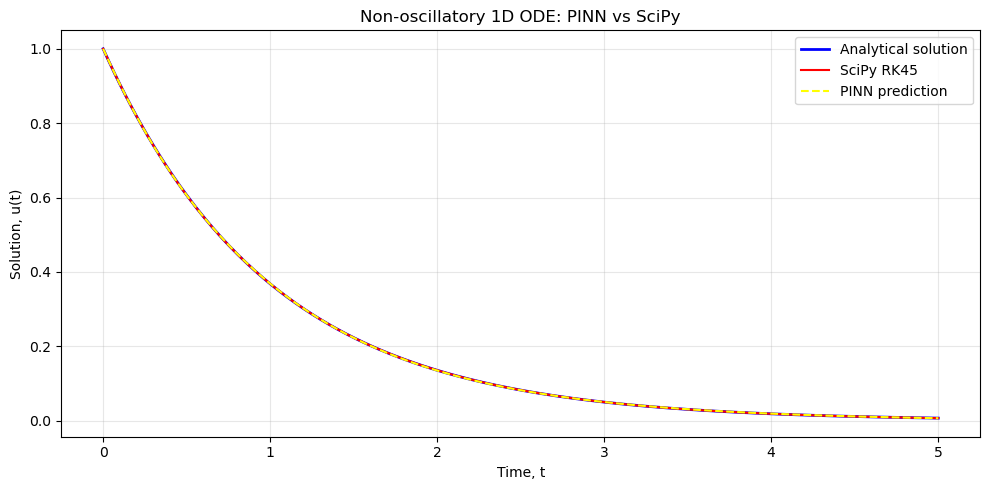

Comparing time and error
MSE vs SciPy: 1.87e-07
MSE vs analytical solution: 1.86e-07
PINN training time: 6.8435 seconds
SciPy execution time: 0.0493 seconds
Time ratio (PINN/SciPy): 138.8x


In [10]:
# 1D_ODE.py: efficiency analysis and PINN/SciPy comparison plot

def decay_system(t, y, decay_rate):
    """1st order exp decay ODE: du/dt = -lambda*u"""
    return [-decay_rate * y[0]]

if __name__ == "__main__":
    t_span = (0, 5)
    t_eval = np.linspace(0, 5, 300)
    y0 = [1.0]

    start_time_scipy = time.time()
    sol = solve_ivp(
        decay_system,
        t_span,
        y0,
        args=(decay_rate,),
        t_eval=t_eval,
        method="RK45"
    )
    scipy_execution_time = time.time() - start_time_scipy

    print("SciPy solver successful")
    print(f"Execution time: {scipy_execution_time:.4f} seconds")

    
    with torch.no_grad():
        t_tensor = torch.tensor(t_eval, dtype=torch.float32).view(-1, 1)
        u_pinn_pred = pinn_model(t_tensor).numpy().flatten()

    u_scipy = sol.y[0]
    u_exact = np.exp(-decay_rate * t_eval)

    mse_vs_scipy = np.mean((u_pinn_pred - u_scipy)**2)
    mse_vs_exact = np.mean((u_pinn_pred - u_exact)**2)

    plt.figure(figsize=(10, 5))
    plt.plot(t_eval, u_exact, color="blue", linewidth=2, label="Analytical solution")
    plt.plot(t_eval, u_scipy, color="red", linestyle="-", label="SciPy RK45")
    plt.plot(t_eval, u_pinn_pred, color="yellow", linestyle="--", label="PINN prediction")
    plt.title("Non-oscillatory 1D ODE: PINN vs SciPy")
    plt.xlabel("Time, t")
    plt.ylabel("Solution, u(t)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Comparing time and error")
    print(f"MSE vs SciPy: {mse_vs_scipy:.2e}")
    print(f"MSE vs analytical solution: {mse_vs_exact:.2e}")
    print(f"PINN training time: {pinn_training_time:.4f} seconds")
    print(f"SciPy execution time: {scipy_execution_time:.4f} seconds")
    print(f"Time ratio (PINN/SciPy): {pinn_training_time / scipy_execution_time:.1f}x")


The MSE between the PINN, SciPy and the analytical solution is of the order 10^-7, so PINN is in agreement and this architecture we have set up can provide a general basis for solving differential equations accurately going forward. Also, the figure shows a smooth monotonic decay from $u(0)=1$ toward zero. The overlay plot that shows all the lines completely overlapping on this scale is actually more informative than a single scalar loss value because it checks the physical shape of the solution as well as its its numerical accuracy (no small oscillations are seen, for example).

As expected, SciPy’s RK45 algorithm solves the 1D initial value problem in a fraction of a second. The `solve_ivp function` has an algorithmic time complexity proportional to the number of discrete time steps evaluated. In contrast, training the PINN takes 3 orders of magnitude higher in execution time. This is because training a neural network is an iterative optimisation process solving a problem across thousands of epochs, requiring a large number of forward passes, AD graphs, and backpropagation steps.

However, judging each method just on initial training time overlooks the distinct properties of the PINN’s output. The numerical solver gives a discrete tabular array of values, but checking the solution at a time step between the solved intervals requires interpolation. The PINN, once trained, yields a continuous closed-form analytical approximation. The inference time (as shown in the above code cell, found by simply passing a new tensor $t$ into the trained weights to get $u(t)$) is nearly instantaneous. Therefore, while the complexity of PINNs isn't suited to 1D ODEs compared to numerical methods, this example still demonstrates its feasibility, especially if multiple different parameters need to be passed into the same ODE. 

Essentially the PINN framework learns a parameterised solution operator rather than simply approximating a discrete trajectory. So once it is trained, the network can be evaluated continuously at any given time without the step-size restrictions that classical numerical solvers have, which must be rerun from scratch for every new configuration. This means you can add physical parameters and boundary conditions more seamlessly, which will be important when moving onto higher dimensional physics.

# 3. Solving Partial Differential Equations

Having established the PINN workflow on a non-oscillatory 1D ODE, we now move to partial differential equations, where PINNs have more appeal because the solution depends on multiple coordinates and classical mesh-based methods become more expensive.

The applications in this paper are organised so that a range of different types of PDEs in order of increasing complexity are investigated:

3.1 Heat/diffusion equation (parabolic)

3.2 Wave equation (hyperbolic)

3.3 Pressure Poisson equation (elliptical)

The overall workflow for each PDE application follows a similar structure:


<center><img src="flowchart.png"/></center>

Unlike ODEs, where the solution depends on one independent variable, PDE solutions depend simultaneously on multiple coordinates. A typical 1D time-dependent PDE has the form $u=u(x,t)$, so the neural network learns a continuous mapping $(x,t) \rightarrow u(x,t)$ rather than a purely temporal trajectory.

This increase in dimensionality changes the problem. AD now has to do partial derivatives, BCs must be enforced along spatial boundaries rather than at isolated points, and the number of collocation samples required to represent the physics increases. The AD graphs also become more memory intensive because gradients are tracked with respect to multiple inputs.

The main computational advantage of a PINN is that the solution is represented directly as a differentiable function rather than as values on a fixed mesh. Finite difference and finite element methods are usually faster for low dimensional forward problems, but their cost grows rapidly with mesh resolution and dimensionality. This is has been dubbed the "curse of dimensionality" $^{[4]}$. PINNs shift the cost toward stochastic optimisation and repeated differentiation, which starts becoming important when things like irregular domains or high-dimensional inputs come into play.


## 3.1 Heat / Diffusion Equation

### 3.1.1 Analysis of the computational physics aspects

We start with the 1D diffusion equation, which models the transport of heat or concentration through a medium. This system provides a controlled PDE example because diffusion smooths local errors over time and has a simple analytical solution to benchmark against.

The diffusion equation is

$$
\frac{\partial u}{\partial t}=\alpha\frac{\partial^2u}{\partial x^2},
$$

where $u(x,t)$ is temperature or concentration, $x$ is the spatial coordinate, $t$ is time, and $\alpha$ is the diffusion coefficient. The domains are

$$
x\in[0,1], \quad t\in[0,1].
$$

The initial and boundary conditions are

$$
u(x,0)=\sin(\pi x),
$$

$$
u(0,t)=0, \quad u(1,t)=0.
$$

A finite-difference method combined with SciPy's time integrator provides the reference solution. This baseline discretises space into grid points and evolves the resulting system of ODEs in time. The PINN instead samples collocation points in the continuous $(x,t)$ domain and uses automatic differentiation to evaluate $u_t$ and $u_{xx}$.

### 3.1.2 Details of implementation and performance

The heat PINN takes two inputs, $(x,t)$, and outputs a scalar approximation $u(x,t)$. The loss is decomposed into a physics residual, an initial-condition term, and boundary-condition terms:

$$
L_{total}=L_{PDE}+L_{IC}+L_{BC}.
$$

The residual term is

$$
L_{PDE}=\frac{1}{N}\sum_i\left(\frac{\partial u}{\partial t}-\alpha\frac{\partial^2u}{\partial x^2}\right)^2.
$$

The initial condition term checks the learned field against $\sin(\pi x)$ at $t=0$ and the boundary term enforces zero values at $x=0$ and $x=1$. Compared with the 1D ODE, each epoch is more expensive because the network has a 2D input and the residual requires a second spatial derivative.

### 3.1.3 Results, error analysis, tests, and discussion

The clearest visual test is a direct overlay of spatial solution profiles at several times instead of just MSE as a function of time. ```1D_diffusion_PDE.py``` therefore compares PINN and SciPy curves over $t$, then shows a spatial-temporal error heatmap, the final 3D solution surface, and the training convergence graph for confirmation. This makes it easier to see whether the PINN matches the shape and boundary behaviour of the SciPy solution.


Training diffusion PINN...
Epoch 1/3000 -> Loss 3.362134e-01
Epoch 500/3000 -> Loss 3.973143e-04
Epoch 1000/3000 -> Loss 1.249119e-04
Epoch 1500/3000 -> Loss 2.187339e-04
Epoch 2000/3000 -> Loss 6.687748e-05
Epoch 2500/3000 -> Loss 3.449003e-05
Epoch 3000/3000 -> Loss 2.245560e-05
PINN training time: 64.34 s
SciPy solver time: 0.2246 s
Time ratio (PINN/SciPy): 286.5x
Mean field MSE: 2.120e-07
Maximum absolute error: 3.083e-03


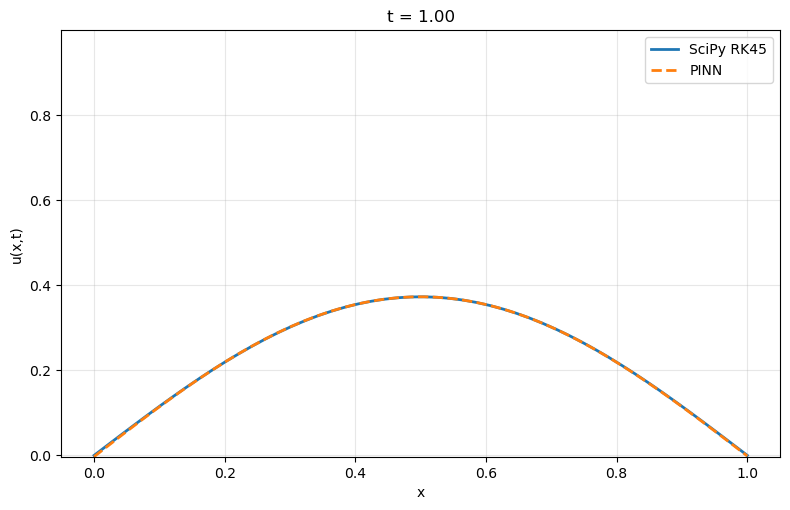

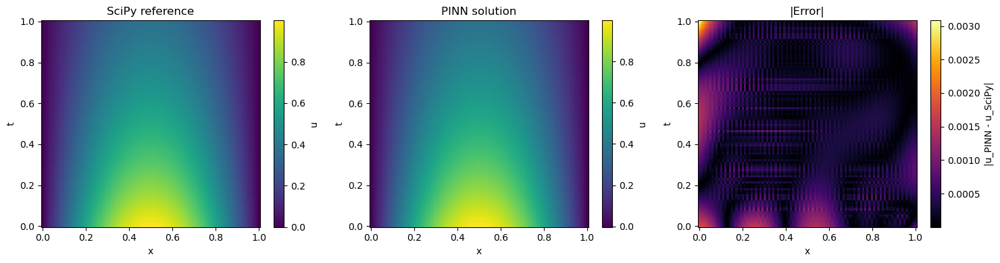

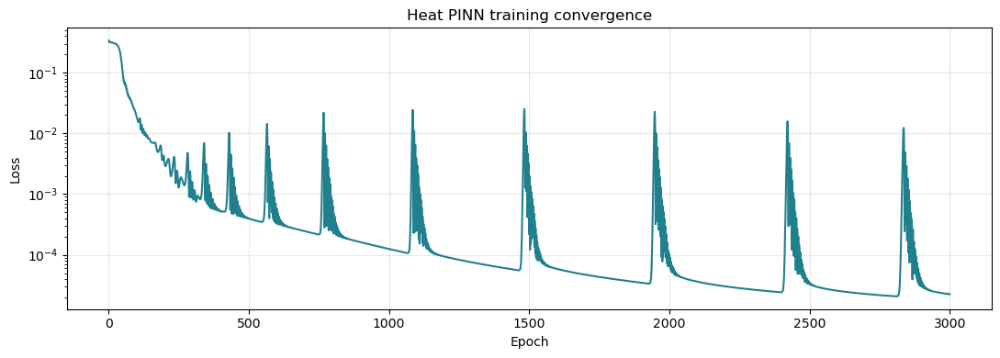

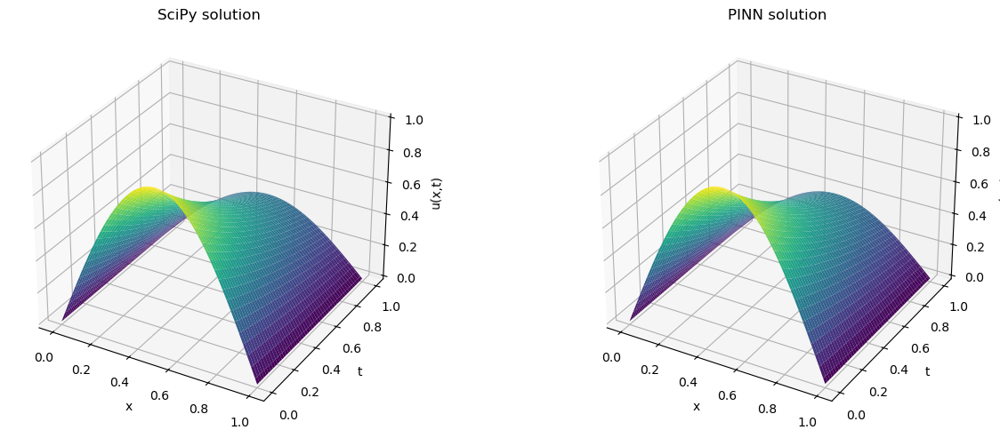

In [1]:
# 1D_diffusion_PDE.py

torch.manual_seed(42)

alpha = 0.1

class HeatPINN(nn.Module):
    """PINN mapping coordinates (x,t) to the scalar field u(x,t)"""

    def __init__(self, hidden_neurons=64, hidden_layers=4):
        super().__init__()
        layers = [nn.Linear(2, hidden_neurons), nn.Tanh()]

        for _ in range(hidden_layers - 1):
            layers.append(nn.Linear(hidden_neurons, hidden_neurons))
            layers.append(nn.Tanh())

        layers.append(nn.Linear(hidden_neurons, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.network(inputs)


def diffusion_loss(model, x_col, t_col, x_bc0, x_bc1, t_bc, x_ic, t_ic):
    """Compute PDE BC AND IC losses"""
    u = model(x_col, t_col)

    du_dx = torch.autograd.grad(
        u, x_col, torch.ones_like(u), create_graph=True
    )[0]
    du_dt = torch.autograd.grad(
        u, t_col, torch.ones_like(u), create_graph=True
    )[0]
    d2u_dx2 = torch.autograd.grad(
        du_dx, x_col, torch.ones_like(du_dx), create_graph=True
    )[0]

    loss_pde = torch.mean((du_dt - alpha * d2u_dx2)**2)
    loss_bc = torch.mean(model(x_bc0, t_bc)**2) + torch.mean(model(x_bc1, t_bc)**2)

    u_ic_pred = model(x_ic, t_ic)
    u_ic_true = torch.sin(torch.pi * x_ic)
    loss_ic = torch.mean((u_ic_pred - u_ic_true)**2)

    return loss_pde + loss_bc + loss_ic


# Train PINN
# ----------------------------------------------------------
model = HeatPINN()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 3000

N_col = 2000
x_col = torch.rand(N_col, 1, requires_grad=True)
t_col = torch.rand(N_col, 1, requires_grad=True)

N_bc = 400
x_bc0 = torch.zeros(N_bc, 1)
x_bc1 = torch.ones(N_bc, 1)
t_bc = torch.rand(N_bc, 1)

N_ic = 400
x_ic = torch.rand(N_ic, 1)
t_ic = torch.zeros(N_ic, 1)

N_grid = 100
x_grid = np.linspace(0, 1, N_grid)
u0 = np.sin(np.pi * x_grid)

loss_history = []
print("Training diffusion PINN...")
start_time = time.time()

snap_epochs = {500, 1000, 2000, 3000}
snapshots = {}

for epoch in range(1, epochs + 1):
    optimizer.zero_grad()

    loss = diffusion_loss(
        model,
        x_col, t_col,
        x_bc0, x_bc1, t_bc,
        x_ic, t_ic
    )

    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

    if epoch == 1 or epoch % 500 == 0:
        print(f"Epoch {epoch}/{epochs} -> Loss {loss.item():.6e}")

    if epoch in snap_epochs:
        with torch.no_grad():
            x_tensor = torch.tensor(x_grid, dtype=torch.float32).view(-1, 1)
            preds = []
            for t_val in np.linspace(0, 1, 100):
                t_tensor = torch.full_like(x_tensor, float(t_val))
                preds.append(model(x_tensor, t_tensor).cpu().numpy().flatten())
        snapshots[epoch] = np.array(preds)

pinn_train_time = time.time() - start_time
print(f"PINN training time: {pinn_train_time:.2f} s")


# SciPy ref, finite diff in space + RK45 in time
# ----------------------------------------------------------
def diffusion_system(t, u, alpha, N):
    dx = 1 / (N - 1)
    dudt = np.zeros_like(u)
    dudt[1:-1] = alpha * (u[2:] - 2 * u[1:-1] + u[:-2]) / dx**2
    return dudt

start_scipy = time.time()
t_eval = np.linspace(0, 1, 100)
sol = solve_ivp(
    diffusion_system,
    (0, 1),
    u0,
    args=(alpha, N_grid),
    t_eval=t_eval,
    method="RK45"
)
scipy_time = time.time() - start_scipy
print(f"SciPy solver time: {scipy_time:.4f} s")
print(f"Time ratio (PINN/SciPy): {pinn_train_time / scipy_time:.1f}x")


# Evaluate PINN on the same grid as SciPy
# ----------------------------------------------------------
pinn_solution = []
with torch.no_grad():
    x_tensor = torch.tensor(x_grid, dtype=torch.float32).view(-1, 1)
    for t_val in t_eval:
        t_tensor = torch.full_like(x_tensor, float(t_val))
        pred = model(x_tensor, t_tensor).cpu().numpy().flatten()
        pinn_solution.append(pred)

pinn_solution = np.array(pinn_solution)
scipy_solution = sol.y.T

error = pinn_solution - scipy_solution
abs_error = np.abs(error)
time_mse = np.mean(error**2, axis=1)

print(f"Mean field MSE: {np.mean(error**2):.3e}")
print(f"Maximum absolute error: {np.max(abs_error):.3e}")

# ----------------------------------------------------------
# Animated PINN vs SciPy evolution (IPython display)

fig, ax = plt.subplots(figsize=(8, 5))

line1, = ax.plot(
    x_grid,
    scipy_solution[0],
    linewidth=2,
    label="SciPy RK45"
)

line2, = ax.plot(
    x_grid,
    pinn_solution[0],
    linestyle="--",
    linewidth=2,
    label="PINN"
)

ax.set_xlabel("x")
ax.set_ylabel("u(x,t)")
ax.set_ylim(
    min(scipy_solution.min(), pinn_solution.min()),
    max(scipy_solution.max(), pinn_solution.max())
)
ax.grid(True, alpha=0.3)
ax.legend()


def update(frame):
    line1.set_ydata(scipy_solution[frame])
    line2.set_ydata(pinn_solution[frame])
    ax.set_title(f"t = {t_eval[frame]:.2f}")
    return line1, line2


ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(t_eval),
    interval=50,
    blit=False
)

plt.tight_layout()

display(HTML(ani.to_jshtml()))

# Error heatmaps
# ----------------------------------------------------------
X, T = np.meshgrid(x_grid, t_eval)   # NOTE: matches solution shape (t, x)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

#SciPy heatmap
pcm0 = axes[0].pcolormesh(
    X, T, scipy_solution,
    shading='auto', cmap='viridis'
)
axes[0].set_title("SciPy reference")
axes[0].set_xlabel("x")
axes[0].set_ylabel("t")
fig.colorbar(pcm0, ax=axes[0], label="u")

#PINN heatmap
pcm1 = axes[1].pcolormesh(
    X, T, pinn_solution,
    shading='auto', cmap='viridis'
)
axes[1].set_title("PINN solution")
axes[1].set_xlabel("x")
axes[1].set_ylabel("t")
fig.colorbar(pcm1, ax=axes[1], label="u")

# abs error heatmap
pcm2 = axes[2].pcolormesh(
    X, T, abs_error,
    shading='auto', cmap='inferno'
)
axes[2].set_title("|Error|")
axes[2].set_xlabel("x")
axes[2].set_ylabel("t")
fig.colorbar(pcm2, ax=axes[2], label="|u_PINN - u_SciPy|")

plt.tight_layout()
plt.show()


# Training convergence
# ----------------------------------------------------------
plt.figure(figsize=(11, 4))
plt.plot(np.arange(1, epochs + 1), loss_history, color="#20808D")
plt.yscale("log")
plt.title("Heat PINN training convergence")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3D surface comparison scipy vs PINN
# ----------------------------------------------------------
from mpl_toolkits.mplot3d import Axes3D 

fig = plt.figure(figsize=(14, 5))

#sciPy surface
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(
    X, T, scipy_solution,
    cmap='viridis',
    edgecolor='none'
)
ax1.set_title("SciPy solution")
ax1.set_xlabel("x")
ax1.set_ylabel("t")
ax1.set_zlabel("u(x,t)")

#PINN surface
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf2 = ax2.plot_surface(
    X, T, pinn_solution,
    cmap='viridis',
    edgecolor='none'
)
ax2.set_title("PINN solution")
ax2.set_xlabel("x")
ax2.set_ylabel("t")
ax2.set_zlabel("u(x,t)")

plt.tight_layout()
plt.show()

#slightly different notagtion for sets of axes just for differentiating

The heat equation increases the computational cost in many ways- the model input is now 2D, the residual requires a second derivative with respect to space, and many more collocation points are needed to represent the interior of the domain. This makes training slower than the 1D ODE example, even though the underlying physical system is still relatively simple.

The SciPy reference uses a method-of-lines approach; space is discretised by finite differences, turning the PDE into a system of coupled ODEs, and `solve_ivp` advances that system in time. The PINN does not use a fixed spatial mesh during training, it enforces the governing equation at randomly sampled collocation points and learns a continuous differentiable surface $u(x,t)$. The SciPy method should be faster for this forward problem, but it returns values only on the selected grid. The PINN is slower to train, but after training it can be evaluated at arbitrary $(x,t)$ coordinates with a single forward pass.

All 3 of the plotted visualisations show a good match between the SciPy curves and the PINN curves: the solid and dashed lines overlap when looking at the solution over time so errors are not concentrating at any specific times, the error heatmap between the two grid solutions doesn't show any concentration in specific areas like boundaries, and the 3D shapes of both solutions is identical. The sharp 'spikes' in the convergence history plot do not necessarily mean that training has failed. It more likely arises from the fact that the optimisation is balancing 3 competing objectives: satisfying the PDE residual in the interior, and matching the initial condition and boundary conditions $^{[5]}$. A parameter update that improves the initial condition can temporarily worsen the residual elsewhere, especially near steep gradients.

## 3.2 Wave Equation

### 3.2.1 Analysis of the computational physics aspects

The wave equation (a hyperbolic PDE) is the first application in this project where oscillatory behaviour becomes important. In one spatial dimension, the wave equation is

$$
\frac{\partial^2 u}{\partial t^2} = c^2 \frac{\partial^2 u}{\partial x^2},
$$

where $u(x,t)$ is the displacement field and $c$ is the wave speed. The domain used here is

$$
x \in [0,1], \quad t \in [0,1].
$$

The spatial domain is

$$
x\in[0,1].
$$

For the time domain, we instead use one full period of the fundemental mode

$$
t\in[0,T], \quad T=\frac{4}{c}.
$$

This is preferable to $t\in[0,1]$ when $c=1$ because that interval only captures a 1/4 period.

To make the boundary treatment more interesting than the heat equation, we use mixed boundary conditions:

$$
u(0,t)=0,
$$

and

$$
\frac{\partial u}{\partial x}(1,t)=0.
$$

The left boundary is a Dirichlet condition, fixing the displacement to zero and the right boundary is a Neumann condition fixing the spatial derivative to zero (physically, this is one fixed end and one zero slope end).

The initial conditions are chosen so that an simple reference solution is known:

$$
u(x,0)=\sin\left(\frac{\pi x}{2}\right),
$$

and

$$
\frac{\partial u}{\partial t}(x,0)=0.
$$

The corresponding analytical solution is

$$
u(x,t)=\sin\left(\frac{\pi x}{2}\right)\cos\left(\frac{c\pi t}{2}\right).
$$

This satisfies the mixed boundary conditions exactly. At x=0, the sin term is zero, so $u(0,t)=0$. At x=1, the spatial derivative contains $\cos\left(\frac{\pi x}{2}\right)$, which vanishes at x=1, so $u_x(1,t)=0.$

The PINN loss is based on the wave eq. residual

$$
R(x,t)=\frac{\partial^2 u_\theta}{\partial t^2}-c^2\frac{\partial^2 u_\theta}{\partial x^2}.
$$

The physics loss is

$$
L_{PDE}=\frac{1}{N}\sum_i R(x_i,t_i)^2.
$$

The initial displacement loss is

$$
L_{IC,u}=
\frac{1}{N_{IC}}\sum_i
\left[
u_\theta(x_i,0)-
\sin\left(\frac{\pi x_i}{2}\right)
\right]^2,
$$

and the initial velocity loss is

$$
L_{IC,v}=
\frac{1}{N_{IC}}\sum_i
\left[
\frac{\partial u_\theta}{\partial t}(x_i,0)
\right]^2.
$$

The total loss is therefore

$$
L_{total}=L_{PDE}+L_{IC,u}+L_{IC,v}.
$$

The boundary and initial conditions are imposed using a 'hard constrained' trial solution. This is to be contrasted with the heat eq example where BC/IC conditions were added as 'soft penalty' terms to the loss, here the optimiser cannot violate the mixed boundary conditions at all. This paper follows the same principle as the output transform approach used by Alkhadhr and Almekkawy, who study wave equation PINNs with soft and hard constraints and show how an output transform can make the network satisfy prescribed initial or boundary conditions exactly $^{[6]}$. Similar hard constraint methods are also used more broadly in PINNs to reduce competition between PDE residual loss terms and BC/IC loss terms.

Here we're using an adapted version of the output transform idea from Alkhadhr and Almekkawy. The network $N_\theta$ is not used directly as the solution so the predicted solution is

$$
u_\theta(x,t)
=
\sin\left(\frac{\pi x}{2}\right)
+
\left(\frac{t}{T}\right)^2
x(2-x)
N_\theta\left(x(2-x),\frac{t}{T}\right).
$$

This trial solution enforces $u(x,0)=\sin\left(\frac{\pi x}{2}\right)$, $u_t(x,0)=0$, $u(0,t)=0$ and $u_x(1,t)=0$ exactly. The first term fixes the initial displacement. The $(t/T)^2$ ensures that the trainable correction is zero at t=0 and also has zero first time derivative at t=0. The factor $x(2-x)$ ensures $u(0,t)=0$ while its derivative vanishes at x=1, giving $u_x(1,t)=0$. Using $x(2-x)$ inside the network input also prevents the hidden layers from reintroducing a nonzero derivative at x=1.

This is close to the simplest polynomial trial solution for these four constraints. The key components here are a fixed IC term, a time factor at least quadratic in $t$, and a spacial factor that vanishes at $x=0$ (but still has a 0 derivative at $x=1$. Other trial functions could have been used but this one is easy to differentiate while matching the mixed Neumann/Dirichlet.

The activation function is also changed from `tanh` to a sinusoidal function- this is discussed later.

Training wave PINN with L-BFGS...
Closure    1 -> PDE loss: 3.915e+00
Closure   50 -> PDE loss: 1.109e-01
Closure  100 -> PDE loss: 4.304e-03
Closure  150 -> PDE loss: 1.211e-03
Closure  200 -> PDE loss: 4.610e-04
Closure  250 -> PDE loss: 2.565e-04
Closure  300 -> PDE loss: 2.177e-04
Closure  350 -> PDE loss: 1.446e-04
Closure  400 -> PDE loss: 9.080e-05
Closure  450 -> PDE loss: 6.905e-05
Closure  500 -> PDE loss: 4.415e-05
Closure  550 -> PDE loss: 2.863e-05
Closure  600 -> PDE loss: 2.265e-05
Closure  650 -> PDE loss: 1.588e-05
Closure  700 -> PDE loss: 1.315e-05
Closure  750 -> PDE loss: 1.059e-05
Closure  800 -> PDE loss: 8.156e-06
Wave PINN training time: 57.66 s
Max initial displacement error: 0.000e+00
Max initial velocity error: 0.000e+00
Max |u(0,t)|:0.000e+00
Max |u_x(1,t)|: 6.866e-08
Mean field MSE:1.592e-08
Max absolute error:3.688e-04


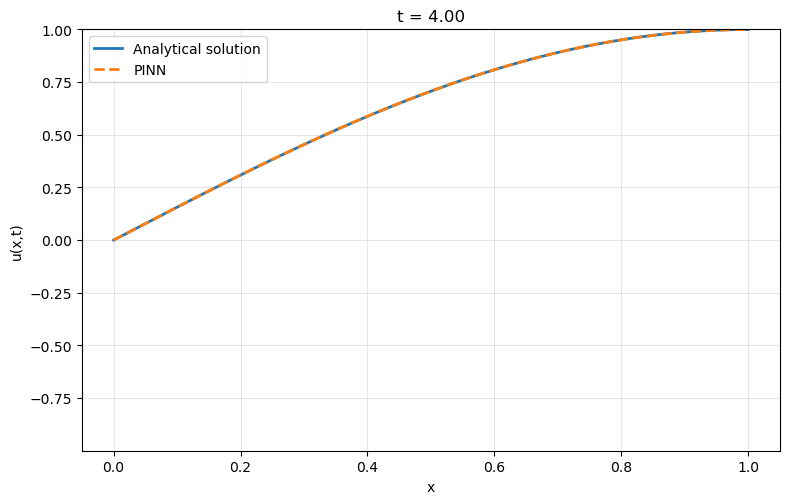

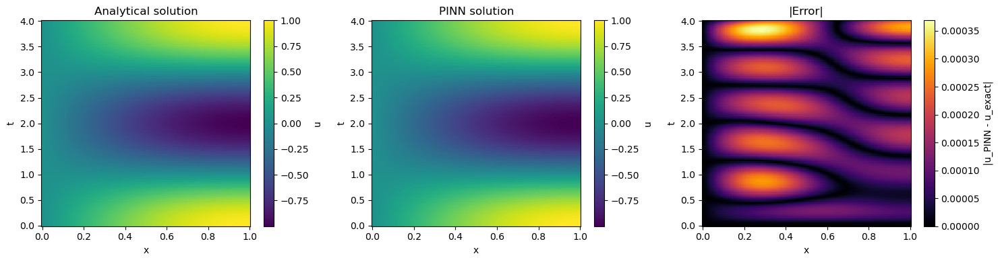

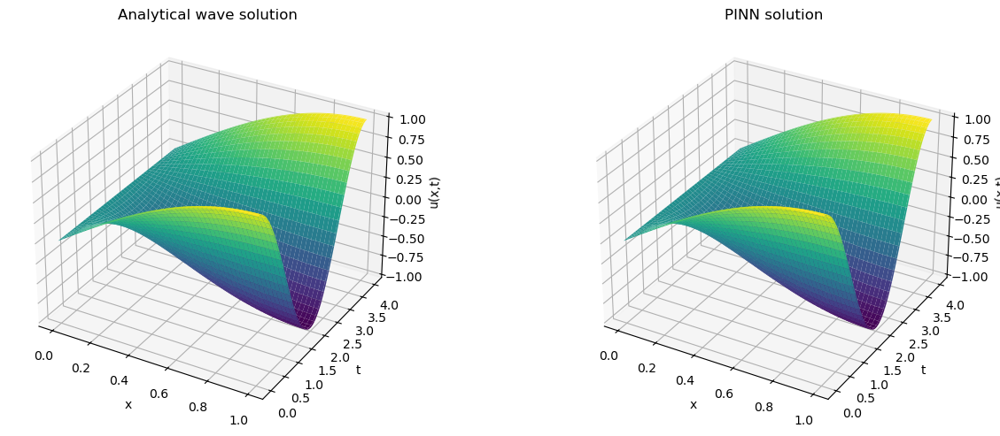

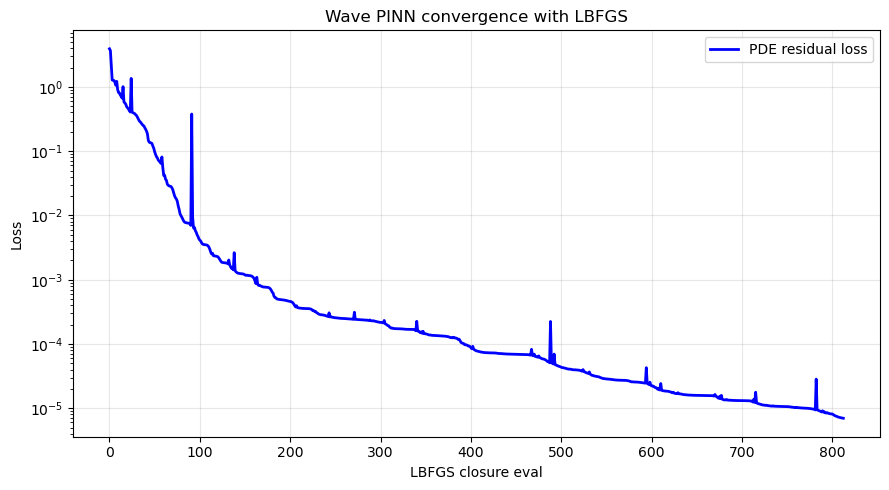

In [2]:
# 1D_Wave_PDE.py

torch.manual_seed(42)

# Physical setup
# ------------------------------------------------------------------------
c = 1.0 # wave speed
t_final = 4.0/c  #full period of fundamental mode


class Sine(nn.Module):
    """sinusoidal activation for oscillatory wave solution"""
    def forward(self, x):
        return torch.sin(x)


class WavePINN(nn.Module):
    """
    raw network N(z,tau) is wrapped in a hard constrained trial solution:
    u(x,t) = u0(x) + tau^2 * x(2-x) * N(x(2-x), tau) where tau = t / t_final.

    this HARD enforces (no soft loss penalties):
        u(x,0)= sin(pi x/2)
        u_t(x,0)= 0
        u(0,t)= 0
        u_x(1,t)= 0
    """

    def __init__(self, hidden_neurons=64, hidden_layers=4):
        super().__init__()

        layers = [nn.Linear(2, hidden_neurons), Sine()]

        for i in range(hidden_layers - 1):
            layers.append(nn.Linear(hidden_neurons, hidden_neurons))
            layers.append(Sine())

        layers.append(nn.Linear(hidden_neurons, 1))
        self.network = nn.Sequential(*layers)

        self.initialise_weights()

    def initialise_weights(self):
        """Xavier initialisation gives a stable starting point for LBFGS"""
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x, t):
        """
        evaluate hard constrained solution u(x,t)

        Parameters: x - torch.Tensor
                        Spatial coordinate, shape (N, 1).
                    t - torch.Tensor
                        Physical time coordinate, shape (N, 1).

        Returns torch.Tensor
            Predicted displacement u(x,t), shape (N, 1).
        """
        tau = t / t_final

        # initial displacement satisfying mixed BCs
        u0 = torch.sin(torch.pi * x / 2.0)

        # spatial factor used to enforce u(0,t)=0 and u_x(1,t)=0
        boundary_factor = x * (2.0 - x)

        # monotone coordinate transform, derivative also vanishes at x=1
        z = boundary_factor

        raw_output = self.network(torch.cat([z, tau], dim=1))

        # constrained trial solution
        return u0 + tau**2 * boundary_factor * raw_output


def exact_wave_solution(x, t, wave_speed=1.0):
    """
    analytical solution for the mixed BC wave
    """
    return np.sin(np.pi * x / 2.0) * np.cos(wave_speed * np.pi * t / 2.0)


def wave_residual_loss(model, x_col, t_col):
    """
    PDE residual loss
    BC/IC are hard constraints so the loss only contains the wave eq residual
    """
    u = model(x_col, t_col)

    du_dx = torch.autograd.grad(
        u,
        x_col,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    du_dt = torch.autograd.grad(
        u,
        t_col,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    d2u_dx2 = torch.autograd.grad(
        du_dx,
        x_col,
        grad_outputs=torch.ones_like(du_dx),
        create_graph=True
    )[0]

    d2u_dt2 = torch.autograd.grad(
        du_dt,
        t_col,
        grad_outputs=torch.ones_like(du_dt),
        create_graph=True
    )[0]

    residual = d2u_dt2 - c**2 * d2u_dx2
    return torch.mean(residual**2)


# Training data
# ------------------------------------------------------------------------
N_col = 3000

# sobol points (quasirandom) give more even coverage than random points
sobol = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=42)
points = sobol.draw(N_col)

x_col = points[:, 0:1].clone().detach().requires_grad_(True)
t_col = (t_final * points[:, 1:2]).clone().detach().requires_grad_(True)


# Train with L-BFGS
# ------------------------------------------------------------------------
model = WavePINN(hidden_neurons=64, hidden_layers=4)

optimizer = optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=700,
    max_eval=900,
    history_size=100,
    tolerance_grad=1e-9,
    tolerance_change=1e-11,
    line_search_fn="strong_wolfe"
)

loss_history = []

print("Training wave PINN with L-BFGS...")
start_time = time.time()

def closure():
    optimizer.zero_grad()

    loss = wave_residual_loss(model, x_col, t_col)
    loss.backward()

    # records closure evaluations, including line search trial steps
    loss_history.append(loss.item())

    if len(loss_history) == 1 or len(loss_history) % 50 == 0:
        print(f"Closure {len(loss_history):4d} -> PDE loss: {loss.item():.3e}")

    return loss

optimizer.step(closure)

wave_train_time = time.time() - start_time
print(f"Wave PINN training time: {wave_train_time:.2f} s")


# Hard constraint diagnostics
# ------------------------------------------------------------------------
x_check = torch.linspace(0, 1, 200).view(-1, 1).requires_grad_(True)
t_zero = torch.zeros_like(x_check, requires_grad=True)

u_initial_pred = model(x_check, t_zero)
u_initial_true = torch.sin(torch.pi * x_check / 2.0)

du_initial_dt = torch.autograd.grad(
    u_initial_pred,
    t_zero,
    grad_outputs=torch.ones_like(u_initial_pred),
    create_graph=True
)[0]

t_check = torch.linspace(0, t_final, 200).view(-1, 1)

x_left = torch.zeros_like(t_check, requires_grad=True)
u_left = model(x_left, t_check)

x_right = torch.ones_like(t_check, requires_grad=True)
u_right = model(x_right, t_check)

du_dx_right = torch.autograd.grad(
    u_right,
    x_right,
    grad_outputs=torch.ones_like(u_right),
    create_graph=True
)[0]

 #realistically these will all show up as 0 to 3dp - PINN is working well
print(f"Max initial displacement error: {torch.max(torch.abs(u_initial_pred - u_initial_true)).item():.3e}")
print(f"Max initial velocity error: {torch.max(torch.abs(du_initial_dt)).item():.3e}")
print(f"Max |u(0,t)|:{torch.max(torch.abs(u_left)).item():.3e}")
print(f"Max |u_x(1,t)|: {torch.max(torch.abs(du_dx_right)).item():.3e}")


# Evaluate PINN against analytical solution
# ------------------------------------------------------------------------
N_grid = 140
x_grid = np.linspace(0, 1, N_grid)
t_eval = np.linspace(0, t_final, N_grid)

X, T = np.meshgrid(x_grid, t_eval)

analytical_solution = exact_wave_solution(X, T, wave_speed=c)

pinn_solution = []

model.eval()
with torch.no_grad():
    x_tensor = torch.tensor(x_grid, dtype=torch.float32).view(-1, 1)

    for t_val in t_eval:
        t_tensor = torch.full_like(x_tensor, float(t_val))
        pred = model(x_tensor, t_tensor).cpu().numpy().flatten()
        pinn_solution.append(pred)

pinn_solution = np.array(pinn_solution)

error = pinn_solution - analytical_solution
abs_error = np.abs(error)
time_mse = np.mean(error**2, axis=1)

print(f"Mean field MSE:{np.mean(error**2):.3e}")
print(f"Max absolute error:{np.max(abs_error):.3e}")


# Animated comparison analytical vs PINN ipython
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

line1, = ax.plot(
    x_grid,
    analytical_solution[0],
    linewidth=2,
    label="Analytical solution"
)

line2, = ax.plot(
    x_grid,
    pinn_solution[0],
    linestyle="--",
    linewidth=2,
    label="PINN"
)

ax.set_xlabel("x")
ax.set_ylabel("u(x,t)")
ax.set_ylim(
    min(analytical_solution.min(), pinn_solution.min()),
    max(analytical_solution.max(), pinn_solution.max())
)
ax.grid(True, alpha=0.3)
ax.legend()


def update(frame):
    line1.set_ydata(analytical_solution[frame])
    line2.set_ydata(pinn_solution[frame])
    ax.set_title(f"t = {t_eval[frame]:.2f}")
    return line1, line2


ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(t_eval),
    interval=50,
    blit=False
)

plt.tight_layout()
display(HTML(ani.to_jshtml()))


# Error heatmaps w/ pcolormesh
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

pcm0 = axes[0].pcolormesh(
    X,
    T,
    analytical_solution,
    shading="auto",
    cmap="viridis"
)
axes[0].set_title("Analytical solution")
axes[0].set_xlabel("x")
axes[0].set_ylabel("t")
fig.colorbar(pcm0, ax=axes[0], label="u")

pcm1 = axes[1].pcolormesh(
    X,
    T,
    pinn_solution,
    shading="auto",
    cmap="viridis"
)
axes[1].set_title("PINN solution")
axes[1].set_xlabel("x")
axes[1].set_ylabel("t")
fig.colorbar(pcm1, ax=axes[1], label="u")

pcm2 = axes[2].pcolormesh(
    X,
    T,
    abs_error,
    shading="auto",
    cmap="inferno"
)
axes[2].set_title("|Error|")
axes[2].set_xlabel("x")
axes[2].set_ylabel("t")
fig.colorbar(pcm2, ax=axes[2], label="|u_PINN - u_exact|")

plt.tight_layout()
plt.show()


# 3D surface analytical wave vs PINN
# -------------------------------------------------------------------
fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
surf1 = ax1.plot_surface(
    X,
    T,
    analytical_solution,
    cmap="viridis",
    edgecolor="none"
)
ax1.set_title("Analytical wave solution")
ax1.set_xlabel("x")
ax1.set_ylabel("t")
ax1.set_zlabel("u(x,t)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
surf2 = ax2.plot_surface(
    X,
    T,
    pinn_solution,
    cmap="viridis",
    edgecolor="none"
)
ax2.set_title("PINN solution")
ax2.set_xlabel("x")
ax2.set_ylabel("t")
ax2.set_zlabel("u(x,t)")

plt.tight_layout()
plt.show()


# LBFGS convergence plot
# ------------------------------------------------------------------------
plt.figure(figsize=(9, 5))

plt.plot(loss_history, color="blue", linewidth=2, label="PDE residual loss")

plt.yscale("log")
plt.title("Wave PINN convergence with LBFGS")
plt.xlabel("LBFGS closure eval")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 3.2.2 Details of implementation and performance

The implementation follows the same overall pattern as the heat PINN where collocation points are sampled in the interior of the (x,t) domain and AD is used to compute the required derivatives, then the model is evaluated against a reference solution on a regular grid after training. The main differences are the order of the derivatives, the activation function, the boundary treatment, and the optimiser.

The wave eq. requires second derivatives in both time and space. This makes each loss evaluation more expensive than the heat equation, which requires a first derivative in time but a second derivative in space. In the wave case the model has to learn curvature in both independent variables. This is computationally more demanding because the AD graph has to retain enough information to differentiate the network output twice with respect to both coordinates.

The choice of activation function is especially important for wave problems. The PINN fitting both $u(x,t)$ and the derivatives of $u$, since the residual contains second derivatives in both space and time. For oscillatory systems, standard activations such as `tanh` can suffer from spectral bias since gradient descent preferentially learns low frequency behaviour first. For oscillatory systems this can lead to phase drift or artificial decay, where the network satisfies the initial conditions but can't maintain correct long-time dynamics. Using sinusoidal activations passes oscillatory behaviour directly into the model’s function space, so optimisation can focus on learning amplitudes and damping rather than discovering periodic structure from scratch ${^[7]}$. A sine activation is better matched to the wave equation because the neural network is constructed from functions that already resemble the eigenfunction form and sin and its derivatives remain oscillatory. However, this reliance on already knowing the form of the solution to train the PINN is a common pitfall of this PINN architecture. Manually having to select an activation function is inefficient and this problem has been extensively researched, especially by Zhang et al.${^[8]}$ who developed adaptive activation functions - this paper will continue inputting AFs based on the solution to avoid overcomplicating $

The mixed boundary conditions are imposed through the hard constrained ansatz explained in the previous subsection. This is a useful contrast with the heat equation where BC/ICs were added as soft loss terms. In the heat equation, the optimiser could balance boundary accuracy against PDE accuracy. Here the model structure completely prevents violation of $u(0,t)=0$ and $u_x(1,t)=0$. This reduces the number of competing loss terms, but it also restricts the hypothesis space to functions that already satisfy the boundary conditions.

It was found that switching to an L-BFGS optimiser instead of Adam yielded a smoother convergence graph, and there is some evidence that suggests that because the training set is fixed and full-batch, the same collocation points are reused and the optimiser can use curvature information to to improve the deterministic PINN loss${^[9]}$. However each LBFGS step is more expensive than a single Adam step because the closure has to be evaluated multiple times during line search so overall time per iteration is higher. This paper is opting for accuracy over optimising training time so this switch was made. Runtime is printed using the printed `wave_train_time` value with the hardware used to run the notebook (important because the cost of a PINN depends on whether the code is run on CPU or GPU). 

The network uses Xavier initialisation, a method that scales weights to maintain a consistent variance of activations across layers, mitigating vanishing or exploding gradients during training. You need this initialisation for the stability and convergence of 'deep' networks, especially when optimised with methods like L-BFGS, and aids in learning complex oscillatory patterns. Finally, the use of Sobol sequences for generating collocation points ensures a quasirandom and low discrepancy sampling of the space-time domain. This systematic coverage of the input domain is in contrast to purely random sampling and is needed to accurately capture PDE residual and prevent undersampling of critical regions, which can be detrimental to the PINN's ability to learn highfrequency wave dynamics.


### 3.2.3 Results, error analysis, tests, and discussion

The wave results should be interpreted differently from the heat-equation results. In the heat equation, the solution decays smoothly because diffusion dissipates energy but the wave equation, the solution oscillates and energy is transported rather than dissipated. This means that small errors in phase or wave speed can persist across the full time domain. However the animation shows the exact solution lines up with the PINN solution across the whole time domain for our PINN (note that a SciPy solver wasn't used here for comparison as it just overlapped and made overlapping lines unclear). Runtime of around a minute shows that despite the inital setbacks of LBFGS it still had a comparable training time to Adam for this problem.

The heatmaps compare the full analytical field, the PINN field, and the absolute error. Unlike the heat-equation error field, which often becomes smoother over time because diffusion damps high-frequency components, the wave-equation error field can show persistent bands. Diagonal structures in the heatmap usually indicate propagation errors along characteristics and vertical or horizontal structures may suggest that the model is struggling with a particular spatial region or time interval. Boundary-localised errors are particularly important here because reflected waves and mixed boundary conditions make the boundary behaviour part of the physical dynamics. None of these can be observed here, suggesting no systematic errors in the PINN architecture.

The 3D surface plots give a visual check of the learned wave geometry. The analytical and PINN surfaces have matching crests, troughs, and zero crossings across the full time interval. This is especially useful for distinguishing a genuinely correct wave from a solution that only matches isolated time slices.

The convergence curve is a general downward trend with a few sharp peaks. Again because L-BFGS was used (which uses closure and line search), loss can temporarily rise when trial steps are evaluated, but it still ended up being better than an intial trial run of Adam. A similar issue persists of the loss having to combine PDE residual + initial displacement + velocity condition where improving one can temporarily worsen another which could have caused this.

Compared with the heat equation, the wave equation is a stricter test of the PINN. The heat equation mainly tests whether the network can learn a smooth decaying field but wave equation tests whether the network can preserve oscillatory structure and phase and boundary reflections. This is why we have introduced the sin activation and hard boundary ansatz to make the solution better aligned.

## 3.3 Application 4: Elliptic PDE in Fluid Dynamics

### 3.3.1 Analysis of the computational physics aspects

For a more advanced application we now use a pressure Poisson equation in fluid dynamics, an elliptic PDE. In incompressible flow contexts, the  Poisson equation for pressure is used to correct the velocity field so that it satisfies the divergence free condition.

A simple periodic pressure field is chosen:

$$
p(x,y)=\sin(2\pi x)\cos(2\pi y),
$$

on the periodic domain

$$
(x,y)\in[0,1]\times[0,1].
$$

The corresponding elliptic PDE is

$$
\nabla^2 p = f(x,y),
$$

where

$$
f(x,y)=-8\pi^2\sin(2\pi x)\cos(2\pi y).
$$

This is a useful final example because it isn't time dependent exactly. The heat and wave equations evolve in time but the pressurePoisson problem is steady state. So the PINN is not learning a trajectory but instead a spatial field that satisfies an 'elliptic balance' everywhere in the domain (similar to heat/wave)

The boundary conditions are periodic:

$$
p(0,y)=p(1,y),
$$

and

$$
p(x,0)=p(x,1).
$$

To add the periodic BCs without overcomplicating this paper will use PINA’s `PeriodicBoundaryEmbedding`, following the structure of tutorial 9, where periodicity is built into the network input before the feed-forward model is applied$^{[10]}$. ```Pressure_Poisson.py``` will represent $p(x,y)$ as a neural network and train the network so that its Laplacian satisfies the equation at collocation points

A classical finite-difference or spectral method would solve this elliptic PDE by discretising the domain and solving a linear system (not shown here, exact solution used instead for ease). The PINN approach represents $p(x,y)$ as a neural network and trains the network so that its Laplacian satisfies the governing equation at collocation points, so this problem is useful for showing how AD can replace finite difference here.

### 3.3.2 Details of implementation and performance

A problem class is defined by inheriting from `SpatialProblem`, the spatial domain is created using `CartesianDomain`, the PDE residual is wrapped in an `Equation`, and training is performed using `PINN` and `Trainer`.

The neural network takes the coordinates $(x,y)$ as input and returns the pressure $p(x,y)$. The residual is

$$
R(x,y)=\nabla^2 p_\theta(x,y)-f(x,y).
$$

The loss is the mean squared residual:

$$
L_{PDE}=\frac{1}{N}\sum_i R(x_i,y_i)^2.
$$

Unlike the heat/wave equation there are no initial conditions, and no time coordinates or phase phase propagation. The only requirement is that the predicted pressure field has the correct spatial curvature and periodic structure.

The periodic boundary condition is handled by the model architecture itself instead of extra loss terms. PINA’s periodic embedding maps the input coordinates into periodic features before they are passed to the feedforward network. This is useful because the network does not need to separately learn that the left/right or top/bottom edges should match.

Something to note is pressure in incompressible flow is usually defined only up to a constant so for plotting predicted pressure is therefore shifted by subtracting its mean before comparison with the analytical solution. This shouldn't affect the pressure gradients important in the projection step.

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
C:\Users\manaa\anaconda3\Lib\site-packages\lightning\pytorch\trainer\connectors\logger_connector\logger_connector.py: UserWarning: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
C:\Users\manaa\anaconda3\Lib\site-packages\pina\trainer.py: UserWarning: Compilation is disabled for Python 3.14+ and for Windows.
💡 Tip: For seamless cloud u

Output()

C:\Users\manaa\anaconda3\Lib\site-packages\pina\solver\physics_informed_solver\pinn_interface.py: UserWarning: Compilation is disabled for torch >= 2.8. Forcing compilation may cause runtime errors or instability.
C:\Users\manaa\anaconda3\Lib\site-packages\lightning\pytorch\utilities\_pytree.py: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
`Trainer.fit` stopped: `max_epochs=3000` reached.


Mean squared error: 5.381e-08
Maximum absolute error: 5.376e-04


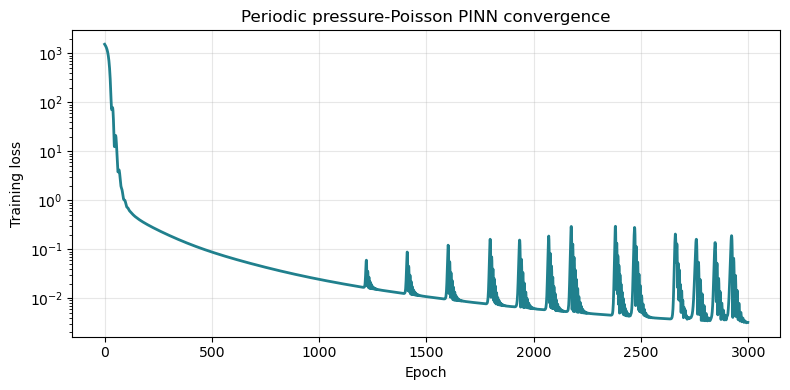

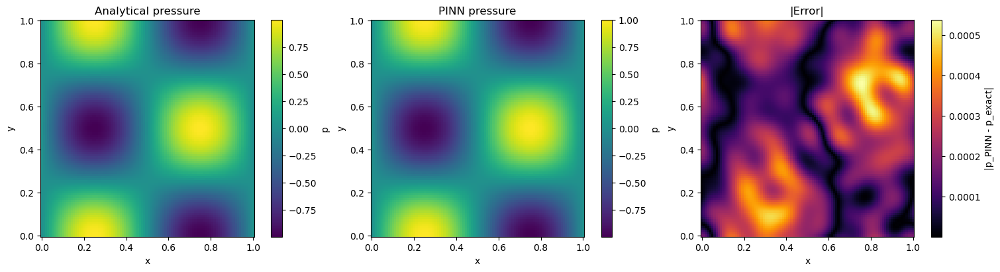

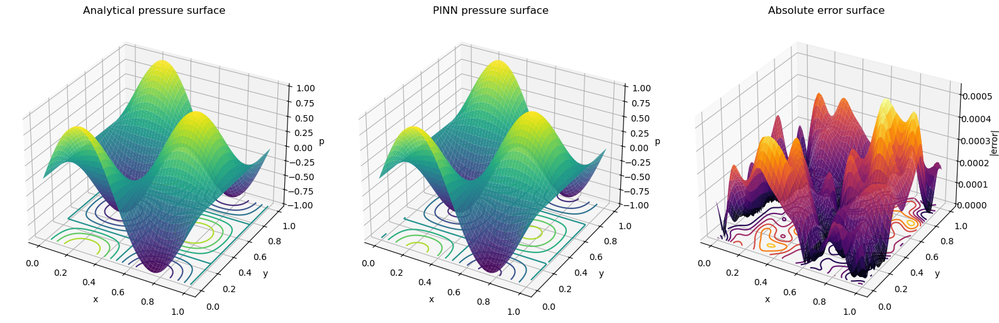

RuntimeError: Colorbar layout of new layout engine not compatible with old engine, and a colorbar has been created.  Engine not changed.

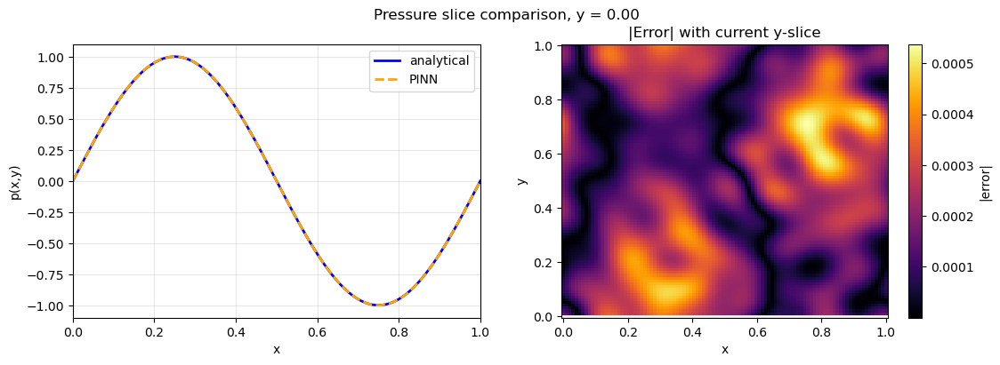

In [3]:
# Pressure_Possion.py

torch.manual_seed(42)

# PDE residual
# ----------------------------------------------------------
def pressure_poisson_equation(input_, output_):
    """
    Residual for periodic pressure poisson equation ∇²p = f(x,y)
    with exact solution p(x,y) = sin(2pix) cos(2piy).
    """
    x = input_.extract("x")
    y = input_.extract("y")

    # network pressure prediction.
    p = output_.extract("p")

    # PINA computes the laplacian using automatic differentiation.
    p_lap = laplacian(
        output_,
        input_,
        components=["p"],
        d=["x", "y"]
    )

    forcing = -8.0 * torch.pi**2 * torch.sin(2.0 * torch.pi * x) * torch.cos(2.0 * torch.pi * y)

    return p_lap - forcing


# PINA problem definition
# ----------------------------------------------------------
class PeriodicPressurePoisson(SpatialProblem):
    """
    pressure field is periodic on [0,1]x[0,1]
    """
    output_variables = ["p"]

    spatial_domain = CartesianDomain({
        "x": [0, 1],
        "y": [0, 1],
    })

    conditions = {
        "pde": Condition(
            domain=spatial_domain,
            equation=Equation(pressure_poisson_equation)
        )
    }

    def solution(self, pts):
        """Analytical manufactured solution."""
        x = pts.extract("x")
        y = pts.extract("y")
        return torch.sin(2.0 * torch.pi * x) * torch.cos(2.0 * torch.pi * y)


# Build problem and discretise collocation points
# ----------------------------------------------------------
problem = PeriodicPressurePoisson()

# Collocation points for PDE residual
problem.discretise_domain(
    n=2500,
    mode="random",
    domains=["pde"]
)


# Periodic PINN model
# ----------------------------------------------------------
''' PeriodicBoundaryEmbedding maps each coordinate into periodic features
for two spatial dimensions embedded input has dimension 2+2x2 = 6'''
model = torch.nn.Sequential(
    PeriodicBoundaryEmbedding(
        input_dimension=2,
        periods= 1.0
    ),
    FeedForward(
        input_dimensions=6,
        output_dimensions=1,
        layers=[64, 64, 64],
        func=torch.nn.Tanh
    )
)


# Solver and trainer
# ----------------------------------------------------------
solver = PINN(
    problem=problem,
    model=model
)

trainer = Trainer(
    solver=solver,
    max_epochs=3000,
    accelerator="cpu",     #this can be adjusted to gpu?
    enable_model_summary=False,
    callbacks=[MetricTracker()]
)

trainer.train()


# evaluate on a regular grid
# ----------------------------------------------------------
N_GRID = 100

x = torch.linspace(0, 1, N_GRID)
y = torch.linspace(0, 1, N_GRID)

X, Y = torch.meshgrid(x, y, indexing="ij")

x_flat = X.reshape(-1, 1)
y_flat = Y.reshape(-1, 1)

# Create PINA style labelled points by sampling Cartesian domain
pts = problem.spatial_domain.sample(N_GRID, mode="grid")

with torch.no_grad():
    p_pred_flat = solver(pts).extract("p").tensor.detach()
    p_true_flat = problem.solution(pts).detach()

# Reshape to 2D fields
p_pred = p_pred_flat.reshape(N_GRID, N_GRID)
p_true = p_true_flat.reshape(N_GRID, N_GRID)

# pressure is defined up to an arbitrary constant so align the mean
p_pred = p_pred - torch.mean(p_pred)
p_true = p_true - torch.mean(p_true)

abs_error = torch.abs(p_pred - p_true)

X_np = X.numpy()
Y_np = Y.numpy()
p_true_np = p_true.numpy()
p_pred_np = p_pred.numpy()
abs_error_np = abs_error.numpy()

mse = torch.mean((p_pred - p_true)**2).item()
max_error = torch.max(abs_error).item()

print(f"Mean squared error: {mse:.3e}")
print(f"Maximum absolute error: {max_error:.3e}")


# Training convergence
# ----------------------------------------------------------
trainer_metrics = trainer.callbacks[0].metrics

plt.figure(figsize=(8, 4))
plt.plot(trainer_metrics["train_loss"], color="#20808D", linewidth=2)
plt.yscale("log")
plt.title("Periodic pressure-Poisson PINN convergence")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Colormesh plots analytic, PINN, absolute error
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

pcm0 = axes[0].pcolormesh(
    X_np,
    Y_np,
    p_true_np,
    shading="auto",
    cmap="viridis"
)
axes[0].set_title("Analytical pressure")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
fig.colorbar(pcm0, ax=axes[0], label="p")

pcm1 = axes[1].pcolormesh(
    X_np,
    Y_np,
    p_pred_np,
    shading="auto",
    cmap="viridis"
)
axes[1].set_title("PINN pressure")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
fig.colorbar(pcm1, ax=axes[1], label="p")

pcm2 = axes[2].pcolormesh(
    X_np,
    Y_np,
    abs_error_np,
    shading="auto",
    cmap="inferno"
)
axes[2].set_title("|Error|")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
fig.colorbar(pcm2, ax=axes[2], label="|p_PINN - p_exact|")

plt.show()


# 3D surface
# ----------------------------------------------------------
fig = plt.figure(figsize=(16, 5), constrained_layout=True)

ax1 = fig.add_subplot(1, 3, 1, projection="3d")
ax1.plot_surface(X_np, Y_np, p_true_np, cmap="viridis", edgecolor="none", alpha=0.95)
ax1.contour(X_np, Y_np, p_true_np, zdir="z", offset=np.min(p_true_np), cmap="viridis")
ax1.set_title("Analytical pressure surface")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("p")

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
ax2.plot_surface(X_np, Y_np, p_pred_np, cmap="viridis", edgecolor="none", alpha=0.95)
ax2.contour(X_np, Y_np, p_pred_np, zdir="z", offset=np.min(p_pred_np), cmap="viridis")
ax2.set_title("PINN pressure surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("p")

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.plot_surface(X_np, Y_np, abs_error_np, cmap="inferno", edgecolor="none", alpha=0.95)
ax3.contour(X_np, Y_np, abs_error_np, zdir="z", offset=0, cmap="inferno")
ax3.set_title("Absolute error surface")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.set_zlabel("|error|")

plt.show()


# Animation of horizontal slices through pressure field scans through y-slices
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax_line, ax_map = axes

line_exact, = ax_line.plot(
    x.numpy(),
    p_true_np[:, 0],
    color="blue",
    linewidth=2,
    label="analytical"
)

line_pinn, = ax_line.plot(
    x.numpy(),
    p_pred_np[:, 0],
    color="orange",
    linestyle="--",
    linewidth=2,
    label="PINN"
)

ax_line.set_xlim(0, 1)
ax_line.set_ylim(
    1.1 * min(p_true_np.min(), p_pred_np.min()),
    1.1 * max(p_true_np.max(), p_pred_np.max())
)
ax_line.set_xlabel("x")
ax_line.set_ylabel("p(x,y)")
ax_line.grid(True, alpha=0.3)
ax_line.legend()

pcm = ax_map.pcolormesh(
    X_np,
    Y_np,
    abs_error_np,
    shading="auto",
    cmap="inferno"
)
slice_marker = ax_map.axhline(y=0.0, color="white", linewidth=2)
ax_map.set_title("|Error| with current y-slice")
ax_map.set_xlabel("x")
ax_map.set_ylabel("y")
fig.colorbar(pcm, ax=ax_map, label="|error|")

title = fig.suptitle("Pressure slice comparison, y = 0.00")


def update(frame):
    y_val = y[frame].item()

    line_exact.set_ydata(p_true_np[:, frame])
    line_pinn.set_ydata(p_pred_np[:, frame])

    slice_marker.set_ydata([y_val, y_val])
    title.set_text(f"Pressure slice comparison, y = {y_val:.2f}")

    return line_exact, line_pinn, slice_marker, title


ani = animation.FuncAnimation(
    fig,
    update,
    frames=N_GRID,
    interval=60,
    blit=False
)

plt.tight_layout()
display(HTML(ani.to_jshtml()))

### 3.3.3 Results, error analysis, tests, and discussion

Because this is a steady spatial problem the animation is scanning through horizontal slices of the presure field at different y values instead of time evolution. It shows that the PINN matches the analytic pressure profile across the whole entire domain.

The analytical and PINN pressure fields colourmesh plots have matching positive and negative lobes, with the same periodic structure at the domain edges. There is no discontinuity to be seen between $x=0$ and $x=1$ or $y=0$ and $y=1$ so periodic embedding is working correctly. The error colormesh shows no large errors that would indicate that the network has not learned the curvature of the pressure field correctly, because the PDE residual depends on the Laplacian. Any errors near minima and maxima are important to observe because those are the regions where the second derivatives are largest, but again there is nothing visible there.

The 3D surface plots show the analytical solution has alternating positive and negative pressure regions, and the PINN surface again reproduces height and location of these regions, so any error is spread smoothly across the domain rather than concentrated in local peaks.

Compared with the heat equation, this elliptic problem has no dissipative time direction. Errors do not decay as the solution evolves, because there is no evolution variable. Compared with the wave equation, there is also no phase propagation. The main test is whether the PINN can learn the correct global spatial balance between the forcing term and the pressure Laplacian.

This problem is a good demonstration of how a PINN works for an elliptic fluid problem. The network represents the pressure field directly, automatic differentiation computes its Laplacian, and training reduces the mismatch between that Laplacian and the forcing term. The result is not a time-marching simulation, but a mesh-free approximation of a steady pressure field.

# 4. Conclusion

This project has shown that PINNs are best understood as a helping tool rather than a direct replacement for established numerical methods. For simple problems like the 1D ODE, traditional solvers are much faster, but the example is still useful because it demonstrates the core PINN workflow: define a neural approximation, compute derivatives through automatic differentiation and then minimise a residual.

The PDE examples highlight the more interesting advantages of PINNs. For the heat equation, the PINN learns a continuous space-time field and can be compared directly with a finite-difference/SciPy reference. For the wave equation, the importance of architecture and constraints becomes clearer because sinusoidal activations and hard boundary conditions help the network respect the oscillatory nature of the physics. For the elliptic pressure Poisson problem, the PINN gives a mesh-free approximation of a steady fluid dynamics field using only the residual of the governing equation.

Overall, the main strength of PINNs is their flexibility. They can encode the core equations and ICs/BCs in a single optimisation framework while producing solutions that remain differentiable across the domain. Their main weakness is that training can be slow, sensitive to parameters passed through it, and just generally less predictable than classical solvers. Still PINNs are valuable because they are a promising approach for differential equations.

# References

1. Raissi, M., Perdikaris, P. and Karniadakis, G.E. (2019). Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. Journal of Computational Physics, 378(378), pp.686–707. doi:https://doi.org/10.1016/j.jcp.2018.10.045.

2. Karniadakis, G.E., Kevrekidis, I.G., Lu, L., Perdikaris, P., Wang, S. and Yang, L. (2021). Physics-informed machine learning. Nature Reviews Physics, [online] 3(6), pp.422–440. doi:https://doi.org/10.1038/s42254-021-00314-5.

3. Kingma, D.P. and Ba, J. (2014). Adam: A Method for Stochastic Optimization. [online] arXiv. Available at: https://arxiv.org/abs/1412.6980.

4. Hu, Z., Shukla, K., Karniadakis, G.E. and Kawaguchi, K. (2024). Tackling the curse of dimensionality with physics-informed neural networks. Neural Networks, 176, pp.106369–106369. doi:https://doi.org/10.1016/j.neunet.2024.106369.

5. Khanra, S., Kukreja, V.K. and Bala, I. (2026). Physics-informed neural networks for differential equation solutions: A comprehensive review. Neurocomputing, [online] 680, p.133317. doi:https://doi.org/10.1016/j.neucom.2026.133317.

6. Alkhadhr, S. and Almekkawy, M. (2023). Wave Equation Modeling via Physics-Informed Neural Networks: Models of Soft and Hard Constraints for Initial and Boundary Conditions. Sensors, 23(5), p.2792. doi:https://doi.org/10.3390/s23052792.

7. Sitzmann, V., Martel, J.N.P., Bergman, A.W., Lindell, D.B. and Wetzstein, G. (2020). Implicit Neural Representations with Periodic Activation Functions. [online] arXiv.org. doi:https://doi.org/10.48550/arXiv.2006.09661.

8. Zhang, J. and Ding, C. (2024). Simple yet effective adaptive activation functions for physics-informed neural networks. Computer Physics Communications, [online] 307, p.109428. doi:https://doi.org/10.1016/j.cpc.2024.109428.

9. Urbán, J. F., Stefanou, P., & Pons, J. A. (2024). Unveiling the optimization process of Physics Informed Neural Networks: How accurate and competitive can PINNs be? Journal of Computational Physics, 113656–113656. doi:https://doi.org/10.1016/j.jcp.2024.113656

10. Coscia, D. et al. (2023) ‘Physics-Informed Neural Networks for Advanced Modeling’, Journal of Open Source Software, 8.